In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Lib


In [32]:
import warnings

warnings.filterwarnings("ignore")

In [33]:
import os
import copy
import random
from pathlib import Path
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


from scipy.ndimage import binary_erosion, distance_transform_edt

import kagglehub
from logging import config

# Set Seed


In [34]:
SEED = 42


def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass


set_seed(SEED)
print(f"Global seed: {SEED}")

Global seed: 42


# Data Augmentation


In [35]:
def build_train_transform(height=256, width=256):
    return A.Compose(
        [
            A.Resize(height=height, width=width),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            A.ShiftScaleRotate(
                shift_limit=0.0625,
                scale_limit=0.15,
                rotate_limit=45,
                border_mode=cv2.BORDER_CONSTANT,
                p=0.5,
            ),
            A.OneOf(
                [
                    A.ElasticTransform(alpha=120, sigma=120 * 0.05, alpha_affine=120 * 0.03, p=0.5),
                    A.GridDistortion(p=0.5),
                    A.OpticalDistortion(distort_limit=1, shift_limit=0.5, p=0.5),
                ],
                p=0.4,
            ),
            A.OneOf(
                [
                    A.RandomBrightnessContrast(
                        brightness_limit=0.1,
                        contrast_limit=0.1,
                        p=0.5
                    ),
                    A.HueSaturationValue(
                        hue_shift_limit=10,
                        sat_shift_limit=15,
                        val_shift_limit=10,
                        p=0.5,
                    ),
                ],
                p=0.3,
            ),
            A.OneOf(
                [
                    A.GaussNoise(var_limit=(10.0, 30.0), p=0.5),
                    A.GaussianBlur(blur_limit=(3, 5), p=0.5),
                ],
                p=0.2,
            ),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            ),
            ToTensorV2(),
        ]
    )

def build_eval_transform(height=256, width=256):
    return A.Compose(
        [
            A.Resize(height=height, width=width),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225),
            ),
            ToTensorV2(),
        ]
    )

# Data Preparation


In [36]:
CLASS_NAMES = {
    0: "background",
    1: "non-neoplastic",
    2: "neoplastic",
}

CLASS_COLORS = {
    0: (0, 0, 0),
    1: (0, 255, 0),
    2: (255, 0, 0),
}


def decode_ground_truth(mask_rgb):
    """
    To RGB mask -> class-index mask 0/1/2.

    Class mapping:
        0 = background      -> black
        1 = non-neoplastic  -> green
        2 = neoplastic      -> red

    Using nearest-color matching to handle or correct any color variations in the mask image.
    This function will convert an RGB mask into a 2D array where each pixel's value corresponds to its class ID (0, 1, or 2).
    """
    mask = np.asarray(mask_rgb)

    if mask.ndim == 2:
        unique_values = np.unique(mask)

        if np.isin(unique_values, [0, 1, 2]).all():
            return mask.astype(np.uint8)

        raise ValueError(
            "Grayscale mask must contain only class IDs 0, 1, 2. "
            f"Found: {unique_values[:20]}"
        )

    if mask.ndim != 3 or mask.shape[-1] != 3:
        raise ValueError(f"Expected HxWx3 RGB mask, got shape={mask.shape}")

    colors = np.array(
        [
            [0, 0, 0],  # background
            [0, 255, 0],  # non-neoplastic
            [255, 0, 0],  # neoplastic
        ],
        dtype=np.float32,
    )

    pixels = mask.astype(np.float32)

    # Shape:
    # pixels -> [H, W, 1, 3]
    # colors -> [1, 1, 3, 3]
    # result -> [H, W, 3]
    diff = pixels[:, :, None, :] - colors[None, None, :, :]

    distances = np.sum(
        diff**2,
        axis=-1,
    )

    class_mask = np.argmin(
        distances,
        axis=-1,
    )

    return class_mask.astype(np.uint8)


def _pick_column(
    df,
    explicit_column=None,
    candidates=None,
    required=True,
):
    if explicit_column is not None:
        if explicit_column not in df.columns:
            raise KeyError(
                f"Column '{explicit_column}' not found. "
                f"Available: {df.columns.tolist()}"
            )

        return explicit_column

    candidates = candidates or []

    normalized = {str(col).strip().lower(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower() in normalized:
            return normalized[candidate.lower()]

    if len(df.columns) == 1:
        return df.columns[0]

    if required:
        raise KeyError(
            "Cannot infer CSV column automatically. "
            f"Available columns: {df.columns.tolist()}"
        )

    return None


class PolypSegmentationDataset(Dataset):
    IMAGE_COLUMN_CANDIDATES = [
        "image",
        "image_name",
        "image_path",
        "filename",
        "file_name",
        "file",
        "id",
    ]

    MASK_COLUMN_CANDIDATES = [
        "mask",
        "mask_name",
        "mask_path",
        "label",
        "label_path",
        "gt",
        "gt_path",
    ]

    def __init__(
        self,
        dataframe,
        image_dir,
        mask_dir=None,
        transform=None,
        image_col=None,
        mask_col=None,
        has_mask=True,
    ):
        self.df = dataframe.reset_index(drop=True).copy()

        self.image_dir = Path(image_dir)

        self.mask_dir = Path(mask_dir) if mask_dir is not None else None

        self.transform = transform
        self.has_mask = has_mask

        self.image_col = _pick_column(
            self.df,
            explicit_column=image_col,
            candidates=self.IMAGE_COLUMN_CANDIDATES,
            required=True,
        )

        if self.has_mask:
            if self.mask_dir is None:
                raise ValueError("mask_dir is required when has_mask=True.")

            self.mask_col = _pick_column(
                self.df,
                explicit_column=mask_col,
                candidates=self.MASK_COLUMN_CANDIDATES,
                required=False,
            )

        else:
            self.mask_col = None

    @staticmethod
    def _resolve_path(root_dir, value):
        candidate = Path(str(value))

        if candidate.is_absolute():
            return candidate

        return Path(root_dir) / str(value)

    def __len__(self):
        return len(self.df)

    def get_image_path(self, index):
        value = self.df.iloc[index][self.image_col]

        return self._resolve_path(
            self.image_dir,
            value,
        )

    def get_mask_path(self, index):
        if not self.has_mask:
            return None

        row = self.df.iloc[index]

        if self.mask_col is not None:
            mask_value = row[self.mask_col]
        else:
            mask_value = row[self.image_col]

        return self._resolve_path(
            self.mask_dir,
            mask_value,
        )

    def __getitem__(self, index):
        image_path = self.get_image_path(index)

        image_bgr = cv2.imread(
            str(image_path),
            cv2.IMREAD_COLOR,
        )

        if image_bgr is None:
            raise FileNotFoundError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB,
        )

        if not self.has_mask:
            if self.transform is not None:
                transformed = self.transform(image=image)

                image = transformed["image"]

            return {
                "image": image,
                "image_path": str(image_path),
                "image_name": image_path.name,
            }

        mask_path = self.get_mask_path(index)

        mask_raw = cv2.imread(
            str(mask_path),
            cv2.IMREAD_UNCHANGED,
        )

        if mask_raw is None:
            raise FileNotFoundError(f"Cannot read mask: {mask_path}")

        if mask_raw.ndim == 3:
            mask_raw = cv2.cvtColor(
                mask_raw,
                cv2.COLOR_BGR2RGB,
            )

        # Nearest-color RGB -> class ID.
        mask = decode_ground_truth(mask_raw)

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                mask=mask,
            )

            image = transformed["image"]
            mask = transformed["mask"]

        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask)

        return {
            "image": image,
            "mask": mask.long(),
            "image_path": str(image_path),
            "mask_path": str(mask_path),
            "image_name": image_path.name,
        }

# Architecture


## Swin-Unet


In [37]:
"""
Swin Transformer backbone for Swin-Unet.

Code structure adapted from the official Microsoft Swin Transformer implementation:
https://github.com/microsoft/Swin-Transformer

The default configuration corresponds to Swin-T:
    patch_size = 4
    embed_dim = 96
    depths = (2, 2, 6, 2)
    num_heads = (3, 6, 12, 24)
    window_size = 7

Pretrained checkpoint example:
    swin_tiny_patch4_window7_224.pth

License/source note:
    Microsoft Swin Transformer is released under the MIT License.
"""

from __future__ import annotations

from typing import List, Sequence, Tuple

import torch
import torch.nn as nn
import torch.utils.checkpoint as checkpoint

try:
    from timm.layers import DropPath, to_2tuple, trunc_normal_
except ImportError:
    # Compatibility with older timm versions.
    from timm.models.layers import DropPath, to_2tuple, trunc_normal_


class Mlp(nn.Module):
    def __init__(
        self,
        in_features: int,
        hidden_features: int | None = None,
        out_features: int | None = None,
        act_layer=nn.GELU,
        drop: float = 0.0,
    ):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features

        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = act_layer()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.fc1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


def window_partition(x: torch.Tensor, window_size: int) -> torch.Tensor:
    """
    Args:
        x: [B, H, W, C]

    Returns:
        windows: [num_windows * B, window_size, window_size, C]
    """
    B, H, W, C = x.shape

    if H % window_size != 0 or W % window_size != 0:
        raise ValueError(
            f"Feature resolution ({H}, {W}) must be divisible by "
            f"window_size={window_size}."
        )

    x = x.view(
        B,
        H // window_size,
        window_size,
        W // window_size,
        window_size,
        C,
    )

    windows = (
        x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size, window_size, C)
    )
    return windows


def window_reverse(
    windows: torch.Tensor,
    window_size: int,
    H: int,
    W: int,
) -> torch.Tensor:
    """Reverse window_partition."""
    B = int(windows.shape[0] / (H * W / window_size / window_size))

    x = windows.view(
        B,
        H // window_size,
        W // window_size,
        window_size,
        window_size,
        -1,
    )

    x = x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)

    return x


class WindowAttention(nn.Module):
    """Window-based multi-head self-attention with relative position bias."""

    def __init__(
        self,
        dim: int,
        window_size: Tuple[int, int],
        num_heads: int,
        qkv_bias: bool = True,
        qk_scale: float | None = None,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ):
        super().__init__()

        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads

        head_dim = dim // num_heads
        self.scale = qk_scale or head_dim**-0.5

        table_size = (2 * window_size[0] - 1) * (2 * window_size[1] - 1)
        self.relative_position_bias_table = nn.Parameter(
            torch.zeros(table_size, num_heads)
        )

        coords_h = torch.arange(window_size[0])
        coords_w = torch.arange(window_size[1])
        coords = torch.stack(torch.meshgrid(coords_h, coords_w, indexing="ij"))
        coords_flatten = torch.flatten(coords, 1)

        relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
        relative_coords = relative_coords.permute(1, 2, 0).contiguous()
        relative_coords[:, :, 0] += window_size[0] - 1
        relative_coords[:, :, 1] += window_size[1] - 1
        relative_coords[:, :, 0] *= 2 * window_size[1] - 1

        relative_position_index = relative_coords.sum(-1)

        self.register_buffer(
            "relative_position_index",
            relative_position_index,
        )

        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
        self.softmax = nn.Softmax(dim=-1)

        trunc_normal_(self.relative_position_bias_table, std=0.02)

    def forward(
        self,
        x: torch.Tensor,
        mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        B_, N, C = x.shape

        qkv = (
            self.qkv(x)
            .reshape(
                B_,
                N,
                3,
                self.num_heads,
                C // self.num_heads,
            )
            .permute(2, 0, 3, 1, 4)
        )

        q, k, v = qkv[0], qkv[1], qkv[2]
        q = q * self.scale

        attn = q @ k.transpose(-2, -1)

        relative_position_bias = (
            self.relative_position_bias_table[self.relative_position_index.view(-1)]
            .view(N, N, -1)
            .permute(2, 0, 1)
            .contiguous()
        )

        attn = attn + relative_position_bias.unsqueeze(0)

        if mask is not None:
            nW = mask.shape[0]

            attn = attn.view(
                B_ // nW,
                nW,
                self.num_heads,
                N,
                N,
            )

            attn = attn + mask.unsqueeze(1).unsqueeze(0)

            attn = attn.view(
                -1,
                self.num_heads,
                N,
                N,
            )

        attn = self.softmax(attn)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)

        x = self.proj(x)
        x = self.proj_drop(x)

        return x


class SwinTransformerBlock(nn.Module):
    """Standard W-MSA / SW-MSA Swin Transformer block."""

    def __init__(
        self,
        dim: int,
        input_resolution: Tuple[int, int],
        num_heads: int,
        window_size: int = 7,
        shift_size: int = 0,
        mlp_ratio: float = 4.0,
        qkv_bias: bool = True,
        qk_scale: float | None = None,
        drop: float = 0.0,
        attn_drop: float = 0.0,
        drop_path: float = 0.0,
        act_layer=nn.GELU,
        norm_layer=nn.LayerNorm,
    ):
        super().__init__()

        self.dim = dim
        self.input_resolution = input_resolution
        self.num_heads = num_heads
        self.window_size = window_size
        self.shift_size = shift_size
        self.mlp_ratio = mlp_ratio

        if min(input_resolution) <= window_size:
            self.shift_size = 0
            self.window_size = min(input_resolution)

        if not 0 <= self.shift_size < self.window_size:
            raise ValueError("shift_size must satisfy 0 <= shift_size < window_size")

        self.norm1 = norm_layer(dim)
        self.attn = WindowAttention(
            dim=dim,
            window_size=to_2tuple(self.window_size),
            num_heads=num_heads,
            qkv_bias=qkv_bias,
            qk_scale=qk_scale,
            attn_drop=attn_drop,
            proj_drop=drop,
        )

        self.drop_path = DropPath(drop_path) if drop_path > 0.0 else nn.Identity()

        self.norm2 = norm_layer(dim)

        mlp_hidden_dim = int(dim * mlp_ratio)
        self.mlp = Mlp(
            in_features=dim,
            hidden_features=mlp_hidden_dim,
            act_layer=act_layer,
            drop=drop,
        )

        if self.shift_size > 0:
            H, W = input_resolution

            img_mask = torch.zeros((1, H, W, 1))

            h_slices = (
                slice(0, -self.window_size),
                slice(-self.window_size, -self.shift_size),
                slice(-self.shift_size, None),
            )

            w_slices = (
                slice(0, -self.window_size),
                slice(-self.window_size, -self.shift_size),
                slice(-self.shift_size, None),
            )

            cnt = 0
            for h in h_slices:
                for w in w_slices:
                    img_mask[:, h, w, :] = cnt
                    cnt += 1

            mask_windows = window_partition(
                img_mask,
                self.window_size,
            )

            mask_windows = mask_windows.view(
                -1,
                self.window_size * self.window_size,
            )

            attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)

            attn_mask = attn_mask.masked_fill(
                attn_mask != 0,
                float(-100.0),
            )
            attn_mask = attn_mask.masked_fill(
                attn_mask == 0,
                float(0.0),
            )
        else:
            attn_mask = None

        self.register_buffer(
            "attn_mask",
            attn_mask,
            persistent=False,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        H, W = self.input_resolution
        B, L, C = x.shape

        if L != H * W:
            raise ValueError(f"Input token length {L} does not match H*W={H*W}.")

        shortcut = x

        x = self.norm1(x)
        x = x.view(B, H, W, C)

        if self.shift_size > 0:
            shifted_x = torch.roll(
                x,
                shifts=(-self.shift_size, -self.shift_size),
                dims=(1, 2),
            )
        else:
            shifted_x = x

        x_windows = window_partition(
            shifted_x,
            self.window_size,
        )

        x_windows = x_windows.view(
            -1,
            self.window_size * self.window_size,
            C,
        )

        attn_windows = self.attn(
            x_windows,
            mask=self.attn_mask,
        )

        attn_windows = attn_windows.view(
            -1,
            self.window_size,
            self.window_size,
            C,
        )

        shifted_x = window_reverse(
            attn_windows,
            self.window_size,
            H,
            W,
        )

        if self.shift_size > 0:
            x = torch.roll(
                shifted_x,
                shifts=(self.shift_size, self.shift_size),
                dims=(1, 2),
            )
        else:
            x = shifted_x

        x = x.view(B, H * W, C)

        x = shortcut + self.drop_path(x)
        x = x + self.drop_path(self.mlp(self.norm2(x)))

        return x


class PatchMerging(nn.Module):
    """Downsample HxW -> H/2 x W/2 and double channel dimension."""

    def __init__(
        self,
        input_resolution: Tuple[int, int],
        dim: int,
        norm_layer=nn.LayerNorm,
    ):
        super().__init__()

        self.input_resolution = input_resolution
        self.dim = dim

        self.reduction = nn.Linear(
            4 * dim,
            2 * dim,
            bias=False,
        )
        self.norm = norm_layer(4 * dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        H, W = self.input_resolution
        B, L, C = x.shape

        if L != H * W:
            raise ValueError("Input feature has wrong token length.")

        if H % 2 != 0 or W % 2 != 0:
            raise ValueError(f"PatchMerging requires even resolution, got ({H}, {W}).")

        x = x.view(B, H, W, C)

        x0 = x[:, 0::2, 0::2, :]
        x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]
        x3 = x[:, 1::2, 1::2, :]

        x = torch.cat(
            [x0, x1, x2, x3],
            dim=-1,
        )

        x = x.view(B, -1, 4 * C)
        x = self.norm(x)
        x = self.reduction(x)

        return x


class BasicLayer(nn.Module):
    """One hierarchical Swin Transformer stage."""

    def __init__(
        self,
        dim: int,
        input_resolution: Tuple[int, int],
        depth: int,
        num_heads: int,
        window_size: int,
        mlp_ratio: float = 4.0,
        qkv_bias: bool = True,
        qk_scale: float | None = None,
        drop: float = 0.0,
        attn_drop: float = 0.0,
        drop_path: float | Sequence[float] = 0.0,
        norm_layer=nn.LayerNorm,
        downsample=None,
        use_checkpoint: bool = False,
    ):
        super().__init__()

        self.use_checkpoint = use_checkpoint

        if isinstance(drop_path, Sequence):
            drop_path_values = list(drop_path)
        else:
            drop_path_values = [drop_path] * depth

        self.blocks = nn.ModuleList(
            [
                SwinTransformerBlock(
                    dim=dim,
                    input_resolution=input_resolution,
                    num_heads=num_heads,
                    window_size=window_size,
                    shift_size=(0 if i % 2 == 0 else window_size // 2),
                    mlp_ratio=mlp_ratio,
                    qkv_bias=qkv_bias,
                    qk_scale=qk_scale,
                    drop=drop,
                    attn_drop=attn_drop,
                    drop_path=drop_path_values[i],
                    norm_layer=norm_layer,
                )
                for i in range(depth)
            ]
        )

        if downsample is not None:
            self.downsample = downsample(
                input_resolution,
                dim=dim,
                norm_layer=norm_layer,
            )
        else:
            self.downsample = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for block in self.blocks:
            if self.use_checkpoint and self.training:
                x = checkpoint.checkpoint(
                    block,
                    x,
                    use_reentrant=False,
                )
            else:
                x = block(x)

        if self.downsample is not None:
            x = self.downsample(x)

        return x


class PatchEmbed(nn.Module):
    """Image to non-overlapping patch tokens."""

    def __init__(
        self,
        img_size: int | Tuple[int, int] = 224,
        patch_size: int | Tuple[int, int] = 4,
        in_chans: int = 3,
        embed_dim: int = 96,
        norm_layer=None,
    ):
        super().__init__()

        img_size = to_2tuple(img_size)
        patch_size = to_2tuple(patch_size)

        patches_resolution = (
            img_size[0] // patch_size[0],
            img_size[1] // patch_size[1],
        )

        self.img_size = img_size
        self.patch_size = patch_size
        self.patches_resolution = patches_resolution
        self.num_patches = patches_resolution[0] * patches_resolution[1]

        self.proj = nn.Conv2d(
            in_chans,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

        self.norm = norm_layer(embed_dim) if norm_layer is not None else None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        _, _, H, W = x.shape

        if (H, W) != self.img_size:
            raise ValueError(f"Expected input size {self.img_size}, got ({H}, {W}).")

        x = self.proj(x)
        x = x.flatten(2).transpose(1, 2)

        if self.norm is not None:
            x = self.norm(x)

        return x


class SwinTransformerBackbone(nn.Module):
    """
    Hierarchical Swin Transformer encoder.

    Default parameters = Swin-T ImageNet-1K configuration.
    """

    def __init__(
        self,
        img_size: int = 224,
        patch_size: int = 4,
        in_chans: int = 3,
        embed_dim: int = 96,
        depths: Sequence[int] = (2, 2, 6, 2),
        num_heads: Sequence[int] = (3, 6, 12, 24),
        window_size: int = 7,
        mlp_ratio: float = 4.0,
        qkv_bias: bool = True,
        qk_scale: float | None = None,
        drop_rate: float = 0.0,
        attn_drop_rate: float = 0.0,
        drop_path_rate: float = 0.2,
        norm_layer=nn.LayerNorm,
        ape: bool = False,
        patch_norm: bool = True,
        use_checkpoint: bool = False,
    ):
        super().__init__()

        self.img_size = img_size
        self.patch_size = patch_size
        self.in_chans = in_chans
        self.embed_dim = embed_dim
        self.depths = tuple(depths)
        self.num_heads = tuple(num_heads)
        self.window_size = window_size

        self.num_layers = len(depths)
        self.ape = ape
        self.patch_norm = patch_norm

        self.num_features = int(embed_dim * 2 ** (self.num_layers - 1))

        self.out_channels = tuple(int(embed_dim * 2**i) for i in range(self.num_layers))

        self.patch_embed = PatchEmbed(
            img_size=img_size,
            patch_size=patch_size,
            in_chans=in_chans,
            embed_dim=embed_dim,
            norm_layer=(norm_layer if patch_norm else None),
        )

        num_patches = self.patch_embed.num_patches
        patches_resolution = self.patch_embed.patches_resolution
        self.patches_resolution = patches_resolution

        if ape:
            self.absolute_pos_embed = nn.Parameter(
                torch.zeros(
                    1,
                    num_patches,
                    embed_dim,
                )
            )
            trunc_normal_(
                self.absolute_pos_embed,
                std=0.02,
            )

        self.pos_drop = nn.Dropout(p=drop_rate)

        dpr = [
            x.item()
            for x in torch.linspace(
                0,
                drop_path_rate,
                sum(depths),
            )
        ]

        self.layers = nn.ModuleList()

        for i_layer in range(self.num_layers):
            layer = BasicLayer(
                dim=int(embed_dim * 2**i_layer),
                input_resolution=(
                    patches_resolution[0] // (2**i_layer),
                    patches_resolution[1] // (2**i_layer),
                ),
                depth=depths[i_layer],
                num_heads=num_heads[i_layer],
                window_size=window_size,
                mlp_ratio=mlp_ratio,
                qkv_bias=qkv_bias,
                qk_scale=qk_scale,
                drop=drop_rate,
                attn_drop=attn_drop_rate,
                drop_path=dpr[sum(depths[:i_layer]) : sum(depths[: i_layer + 1])],
                norm_layer=norm_layer,
                downsample=(PatchMerging if i_layer < self.num_layers - 1 else None),
                use_checkpoint=use_checkpoint,
            )

            self.layers.append(layer)

        self.norm = norm_layer(self.num_features)

        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module: nn.Module) -> None:
        if isinstance(module, nn.Linear):
            trunc_normal_(
                module.weight,
                std=0.02,
            )
            if module.bias is not None:
                nn.init.constant_(
                    module.bias,
                    0,
                )

        elif isinstance(module, nn.LayerNorm):
            nn.init.constant_(
                module.bias,
                0,
            )
            nn.init.constant_(
                module.weight,
                1.0,
            )

    def forward(
        self,
        x: torch.Tensor,
    ) -> Tuple[torch.Tensor, List[torch.Tensor]]:
        """
        Returns:
            bottleneck:
                [B, H/32 * W/32, 768] for Swin-T @ 224.

            skips:
                Token features before each encoder stage:
                stage 0: [B, 56*56, 96]
                stage 1: [B, 28*28, 192]
                stage 2: [B, 14*14, 384]
                stage 3: [B,  7*7,  768]
        """
        x = self.patch_embed(x)

        if self.ape:
            x = x + self.absolute_pos_embed

        x = self.pos_drop(x)

        skips: List[torch.Tensor] = []

        for layer in self.layers:
            skips.append(x)
            x = layer(x)

        x = self.norm(x)

        return x, skips

    def load_pretrained(
        self,
        checkpoint_path: str,
        strict: bool = False,
    ):
        """
        Load an official Microsoft Swin Transformer checkpoint.

        Expected checkpoint:
            swin_tiny_patch4_window7_224.pth

        Classification-only parameters such as `head.*` are ignored.
        The encoder keys keep the same names as Microsoft's implementation.
        """
        checkpoint_data = torch.load(
            checkpoint_path,
            map_location="cpu",
        )

        state_dict = checkpoint_data.get(
            "model",
            checkpoint_data,
        )

        # Remove common wrappers if present.
        cleaned_state_dict = {}

        for key, value in state_dict.items():
            if key.startswith("module."):
                key = key[len("module.") :]

            if key.startswith("backbone."):
                key = key[len("backbone.") :]

            # Classification head is not part of the segmentation backbone.
            if key.startswith("head."):
                continue

            cleaned_state_dict[key] = value

        model_state = self.state_dict()

        compatible_state = {}
        skipped = []

        for key, value in cleaned_state_dict.items():
            if key not in model_state:
                continue

            if model_state[key].shape != value.shape:
                skipped.append(
                    (
                        key,
                        tuple(value.shape),
                        tuple(model_state[key].shape),
                    )
                )
                continue

            compatible_state[key] = value

        msg = self.load_state_dict(
            compatible_state,
            strict=strict,
        )

        print(f"[Swin backbone] Loaded " f"{len(compatible_state)} tensors.")

        if skipped:
            print(
                f"[Swin backbone] Skipped " f"{len(skipped)} shape-mismatched tensors."
            )

        print(f"[Swin backbone] Missing keys: " f"{len(msg.missing_keys)}")
        print(f"[Swin backbone] Unexpected keys: " f"{len(msg.unexpected_keys)}")

        return msg

In [38]:
"""
Swin-Unet model using a Swin Transformer encoder backbone.

Architecture adapted from the official Swin-Unet implementation:
https://github.com/HuCaoFighting/Swin-Unet

Encoder / pretrained weights:
https://github.com/microsoft/Swin-Transformer

The default model is Swin-Unet with a Swin-T encoder:
    img_size = 224
    patch_size = 4
    embed_dim = 96
    depths = (2, 2, 6, 2)
    num_heads = (3, 6, 12, 24)
    window_size = 7
"""

from __future__ import annotations

import copy
from typing import Sequence, Tuple

import torch
import torch.nn as nn
import torch.utils.checkpoint as checkpoint


class PatchExpand(nn.Module):
    """2x token-space upsampling used by the Swin-Unet decoder."""

    def __init__(
        self,
        input_resolution: Tuple[int, int],
        dim: int,
        dim_scale: int = 2,
        norm_layer=nn.LayerNorm,
    ):
        super().__init__()

        self.input_resolution = input_resolution
        self.dim = dim
        self.dim_scale = dim_scale

        self.expand = (
            nn.Linear(
                dim,
                2 * dim,
                bias=False,
            )
            if dim_scale == 2
            else nn.Identity()
        )

        self.norm = norm_layer(dim // dim_scale)

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        H, W = self.input_resolution

        x = self.expand(x)

        B, L, C = x.shape

        if L != H * W:
            raise ValueError(f"Input token length {L} != H*W={H*W}.")

        x = x.view(B, H, W, C)

        # Equivalent to pixel shuffle in token/channel layout.
        x = x.view(
            B,
            H,
            W,
            2,
            2,
            C // 4,
        )

        x = (
            x.permute(
                0,
                1,
                3,
                2,
                4,
                5,
            )
            .contiguous()
            .view(
                B,
                H * 2,
                W * 2,
                C // 4,
            )
        )

        x = x.view(
            B,
            -1,
            C // 4,
        )

        x = self.norm(x)

        return x


class FinalPatchExpandX4(nn.Module):
    """Final 4x expansion from patch resolution back to image resolution."""

    def __init__(
        self,
        input_resolution: Tuple[int, int],
        dim: int,
        dim_scale: int = 4,
        norm_layer=nn.LayerNorm,
    ):
        super().__init__()

        self.input_resolution = input_resolution
        self.dim = dim
        self.dim_scale = dim_scale

        self.expand = nn.Linear(
            dim,
            (dim_scale**2) * dim,
            bias=False,
        )

        self.norm = norm_layer(dim)

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        H, W = self.input_resolution

        x = self.expand(x)

        B, L, C = x.shape

        if L != H * W:
            raise ValueError(f"Input token length {L} != H*W={H*W}.")

        scale = self.dim_scale

        x = x.view(
            B,
            H,
            W,
            scale,
            scale,
            C // (scale**2),
        )

        x = (
            x.permute(
                0,
                1,
                3,
                2,
                4,
                5,
            )
            .contiguous()
            .view(
                B,
                H * scale,
                W * scale,
                C // (scale**2),
            )
        )

        x = x.view(
            B,
            -1,
            self.dim,
        )

        x = self.norm(x)

        return x


class BasicLayerUp(nn.Module):
    """One Swin Transformer decoder stage followed optionally by PatchExpand."""

    def __init__(
        self,
        dim: int,
        input_resolution: Tuple[int, int],
        depth: int,
        num_heads: int,
        window_size: int,
        mlp_ratio: float = 4.0,
        qkv_bias: bool = True,
        qk_scale: float | None = None,
        drop: float = 0.0,
        attn_drop: float = 0.0,
        drop_path: float | Sequence[float] = 0.0,
        norm_layer=nn.LayerNorm,
        upsample=None,
        use_checkpoint: bool = False,
    ):
        super().__init__()

        self.use_checkpoint = use_checkpoint

        if isinstance(drop_path, Sequence):
            drop_path_values = list(drop_path)
        else:
            drop_path_values = [drop_path] * depth

        self.blocks = nn.ModuleList(
            [
                SwinTransformerBlock(
                    dim=dim,
                    input_resolution=input_resolution,
                    num_heads=num_heads,
                    window_size=window_size,
                    shift_size=(0 if i % 2 == 0 else window_size // 2),
                    mlp_ratio=mlp_ratio,
                    qkv_bias=qkv_bias,
                    qk_scale=qk_scale,
                    drop=drop,
                    attn_drop=attn_drop,
                    drop_path=drop_path_values[i],
                    norm_layer=norm_layer,
                )
                for i in range(depth)
            ]
        )

        if upsample is not None:
            self.upsample = upsample(
                input_resolution=input_resolution,
                dim=dim,
                dim_scale=2,
                norm_layer=norm_layer,
            )
        else:
            self.upsample = None

    def forward(
        self,
        x: torch.Tensor,
    ) -> torch.Tensor:
        for block in self.blocks:
            if self.use_checkpoint and self.training:
                x = checkpoint.checkpoint(
                    block,
                    x,
                    use_reentrant=False,
                )
            else:
                x = block(x)

        if self.upsample is not None:
            x = self.upsample(x)

        return x


class SwinUNet(nn.Module):
    """
    Swin-Unet with a configurable Swin encoder.

    Defaults match Swin-T + 3-class semantic segmentation.

    Args:
        img_size:
            Fixed model input size. Official Swin-Unet commonly uses 224.

        num_classes:
            Segmentation classes. Use 3 for:
            background, non-neoplastic, neoplastic.

        pretrained_path:
            Optional Microsoft Swin-T ImageNet-1K checkpoint path.

        pretrained_decoder:
            If True, encoder stage weights are mirrored into compatible
            decoder Swin blocks following the initialization idea used by
            the official Swin-Unet implementation.
    """

    def __init__(
        self,
        img_size: int = 224,
        patch_size: int = 4,
        in_channels: int = 3,
        num_classes: int = 3,
        embed_dim: int = 96,
        depths: Sequence[int] = (2, 2, 6, 2),
        num_heads: Sequence[int] = (3, 6, 12, 24),
        window_size: int = 7,
        mlp_ratio: float = 4.0,
        qkv_bias: bool = True,
        qk_scale: float | None = None,
        drop_rate: float = 0.0,
        attn_drop_rate: float = 0.0,
        drop_path_rate: float = 0.2,
        norm_layer=nn.LayerNorm,
        ape: bool = False,
        patch_norm: bool = True,
        use_checkpoint: bool = False,
        pretrained_path: str | None = None,
        pretrained_decoder: bool = True,
    ):
        super().__init__()

        self.img_size = img_size
        self.patch_size = patch_size
        self.in_channels = in_channels
        self.num_classes = num_classes
        self.embed_dim = embed_dim
        self.depths = tuple(depths)
        self.num_heads = tuple(num_heads)
        self.window_size = window_size
        self.num_layers = len(depths)

        # Encoder: Microsoft Swin Transformer-compatible backbone
        self.encoder = SwinTransformerBackbone(
            img_size=img_size,
            patch_size=patch_size,
            in_chans=in_channels,
            embed_dim=embed_dim,
            depths=depths,
            num_heads=num_heads,
            window_size=window_size,
            mlp_ratio=mlp_ratio,
            qkv_bias=qkv_bias,
            qk_scale=qk_scale,
            drop_rate=drop_rate,
            attn_drop_rate=attn_drop_rate,
            drop_path_rate=drop_path_rate,
            norm_layer=norm_layer,
            ape=ape,
            patch_norm=patch_norm,
            use_checkpoint=use_checkpoint,
        )

        patches_resolution = self.encoder.patches_resolution

        # Same stochastic-depth schedule as encoder.
        dpr = [
            x.item()
            for x in torch.linspace(
                0,
                drop_path_rate,
                sum(depths),
            )
        ]

        # Decoder
        self.layers_up = nn.ModuleList()
        self.concat_back_dim = nn.ModuleList()

        for i_layer in range(self.num_layers):
            encoder_stage = self.num_layers - 1 - i_layer

            dim = int(embed_dim * 2**encoder_stage)

            resolution = (
                patches_resolution[0] // (2**encoder_stage),
                patches_resolution[1] // (2**encoder_stage),
            )

            if i_layer == 0:
                self.concat_back_dim.append(nn.Identity())

                self.layers_up.append(
                    PatchExpand(
                        input_resolution=resolution,
                        dim=dim,
                        dim_scale=2,
                        norm_layer=norm_layer,
                    )
                )

            else:
                self.concat_back_dim.append(
                    nn.Linear(
                        2 * dim,
                        dim,
                    )
                )

                stage_dpr = dpr[
                    sum(depths[:encoder_stage]) : sum(depths[: encoder_stage + 1])
                ]

                self.layers_up.append(
                    BasicLayerUp(
                        dim=dim,
                        input_resolution=resolution,
                        depth=depths[encoder_stage],
                        num_heads=num_heads[encoder_stage],
                        window_size=window_size,
                        mlp_ratio=mlp_ratio,
                        qkv_bias=qkv_bias,
                        qk_scale=qk_scale,
                        drop=drop_rate,
                        attn_drop=attn_drop_rate,
                        drop_path=stage_dpr,
                        norm_layer=norm_layer,
                        upsample=(
                            PatchExpand if i_layer < self.num_layers - 1 else None
                        ),
                        use_checkpoint=use_checkpoint,
                    )
                )

        self.norm_up = norm_layer(embed_dim)

        self.final_up = FinalPatchExpandX4(
            input_resolution=patches_resolution,
            dim=embed_dim,
            dim_scale=4,
            norm_layer=norm_layer,
        )

        self.segmentation_head = nn.Conv2d(
            in_channels=embed_dim,
            out_channels=num_classes,
            kernel_size=1,
            bias=False,
        )

        self.apply(self._init_decoder_weights)

        if pretrained_path is not None:
            self.load_pretrained(
                pretrained_path,
                load_decoder=pretrained_decoder,
            )

    @staticmethod
    def _init_decoder_weights(
        module: nn.Module,
    ) -> None:
        # Encoder initializes itself. Reinitializing it with the same rule is harmless before loading pretrained weights.
        try:
            from timm.layers import trunc_normal_
        except ImportError:
            from timm.models.layers import trunc_normal_

        if isinstance(module, nn.Linear):
            trunc_normal_(
                module.weight,
                std=0.02,
            )
            if module.bias is not None:
                nn.init.constant_(
                    module.bias,
                    0,
                )

        elif isinstance(module, nn.LayerNorm):
            nn.init.constant_(
                module.bias,
                0,
            )
            nn.init.constant_(
                module.weight,
                1.0,
            )

    def forward_up_features(
        self,
        x: torch.Tensor,
        skips: list[torch.Tensor],
    ) -> torch.Tensor:
        for i, layer_up in enumerate(self.layers_up):
            if i == 0:
                x = layer_up(x)
                continue

            skip_index = self.num_layers - 1 - i

            skip = skips[skip_index]

            if x.shape[1] != skip.shape[1]:
                raise ValueError(
                    f"Decoder/skip token mismatch at stage {i}: "
                    f"{x.shape} vs {skip.shape}"
                )

            x = torch.cat(
                [x, skip],
                dim=-1,
            )

            x = self.concat_back_dim[i](x)
            x = layer_up(x)

        x = self.norm_up(x)

        return x

    def tokens_to_feature_map(
        self,
        x: torch.Tensor,
        resolution: Tuple[int, int],
    ) -> torch.Tensor:
        B, L, C = x.shape
        H, W = resolution

        if L != H * W:
            raise ValueError(f"Token length {L} != H*W={H*W}.")

        return x.transpose(1, 2).contiguous().view(B, C, H, W)

    def forward(
        self,
        x: torch.Tensor,
        return_features: bool = False,
    ):
        if x.shape[1] != self.in_channels:
            raise ValueError(
                f"Expected {self.in_channels} input channels, " f"got {x.shape[1]}."
            )

        bottleneck, skips = self.encoder(x)

        decoder_tokens = self.forward_up_features(
            bottleneck,
            skips,
        )

        x = self.final_up(decoder_tokens)

        B, L, C = x.shape

        if L != self.img_size * self.img_size:
            raise ValueError(
                "Final token count does not match output image resolution."
            )

        x = x.view(
            B,
            self.img_size,
            self.img_size,
            C,
        )

        x = x.permute(
            0,
            3,
            1,
            2,
        ).contiguous()

        logits = self.segmentation_head(x)

        if not return_features:
            return logits

        bottleneck_resolution = (
            self.encoder.patches_resolution[0] // (2 ** (self.num_layers - 1)),
            self.encoder.patches_resolution[1] // (2 ** (self.num_layers - 1)),
        )

        bottleneck_map = self.tokens_to_feature_map(
            bottleneck,
            bottleneck_resolution,
        )

        decoder_map = self.tokens_to_feature_map(
            decoder_tokens,
            self.encoder.patches_resolution,
        )

        return logits, {
            "bottleneck": bottleneck_map,
            "decoder": decoder_map,
        }

    def load_pretrained(
        self,
        checkpoint_path: str,
        load_decoder: bool = True,
    ):
        """
        Load Microsoft Swin checkpoint into encoder.

        If load_decoder=True, compatible encoder Swin block weights are
        mirrored into decoder stages, following the official Swin-Unet
        pretraining strategy.
        """

        # 1) Load exact Microsoft-compatible keys into the encoder.
        encoder_msg = self.encoder.load_pretrained(
            checkpoint_path,
            strict=False,
        )

        if not load_decoder:
            return encoder_msg

        # 2) Read checkpoint again to initialize compatible decoder blocks.
        checkpoint_data = torch.load(
            checkpoint_path,
            map_location="cpu",
        )

        state_dict = checkpoint_data.get(
            "model",
            checkpoint_data,
        )

        cleaned = {}

        for key, value in state_dict.items():
            if key.startswith("module."):
                key = key[len("module.") :]

            if key.startswith("backbone."):
                key = key[len("backbone.") :]

            if key.startswith("head."):
                continue

            cleaned[key] = value

        model_state = self.state_dict()

        decoder_state = {}

        # Map encoder layer N -> decoder layer (3-N).
        # Only keys with exact matching names/shapes are loaded.
        for key, value in cleaned.items():
            if not key.startswith("layers."):
                continue

            parts = key.split(".")

            if len(parts) < 3:
                continue

            encoder_stage = int(parts[1])
            decoder_stage = self.num_layers - 1 - encoder_stage

            new_key = f"layers_up.{decoder_stage}." + ".".join(parts[2:])

            if new_key not in model_state:
                continue

            if model_state[new_key].shape != value.shape:
                continue

            decoder_state[new_key] = value

        decoder_msg = self.load_state_dict(
            decoder_state,
            strict=False,
        )

        print(f"[Swin-Unet decoder] Loaded " f"{len(decoder_state)} mirrored tensors.")

        return {
            "encoder": encoder_msg,
            "decoder": decoder_msg,
        }

# Func


## Metrics


In [39]:
def multiclass_dice_score(
    logits,
    targets,
    num_classes=3,
    include_background=False,
    eps=1e-7,
):
    """
    Mean per-class Dice over the batch.

    For each class, samples where both GT and prediction are empty are
    excluded from that class's mean. This prevents rare classes from
    receiving artificial Dice=1 scores simply because the class is absent.
    """
    preds = torch.argmax(logits, dim=1)
    start_class = 0 if include_background else 1
    scores = []

    for class_id in range(start_class, num_classes):
        pred_c = preds == class_id
        target_c = targets == class_id

        intersection = (pred_c & target_c).sum(dim=(1, 2)).float()

        denominator = pred_c.sum(dim=(1, 2)).float() + target_c.sum(dim=(1, 2)).float()

        valid = denominator > 0

        if valid.any():
            score = (2.0 * intersection[valid] + eps) / (denominator[valid] + eps)

            scores.append(score.mean())

    if not scores:
        return torch.tensor(
            0.0,
            device=logits.device,
        )

    return torch.stack(scores).mean()


def hd95_binary(pred_mask, true_mask):
    """
    Compute symmetric HD95 when both GT and prediction contain the class.

    If either side is empty, HD95 is undefined because there are not two
    surfaces to compare, so NaN is returned. Dataset-level evaluation keeps
    using np.nanmean, meaning only valid surface-distance cases contribute.
    """
    pred = np.asarray(pred_mask).astype(bool)
    true = np.asarray(true_mask).astype(bool)

    if not pred.any() or not true.any():
        return np.nan

    pred_surface = pred ^ binary_erosion(pred)
    true_surface = true ^ binary_erosion(true)

    if not pred_surface.any():
        pred_surface = pred

    if not true_surface.any():
        true_surface = true

    dist_to_true = distance_transform_edt(~true_surface)
    dist_to_pred = distance_transform_edt(~pred_surface)

    d1 = dist_to_true[pred_surface]
    d2 = dist_to_pred[true_surface]
    distances = np.concatenate([d1, d2])

    return float(np.percentile(distances, 95))


def _safe_divide(numerator, denominator):
    if denominator == 0:
        return np.nan
    return float(numerator / denominator)

## Loss


In [40]:
class GeneralizedDiceLoss(nn.Module):
    """Generalized Dice Loss (GDL): Automatically balances class weights based on the inverse square of the true area."""

    def __init__(self, num_classes=3, smooth=1e-6, ignore_index=None):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.ignore_index = ignore_index

    def forward(self, logits, targets):
        probabilities = torch.softmax(logits, dim=1)

        if self.ignore_index is not None:
            valid_mask = targets != self.ignore_index
            safe_targets = torch.where(valid_mask, targets, torch.zeros_like(targets))
        else:
            valid_mask = torch.ones_like(targets, dtype=torch.bool)
            safe_targets = targets

        targets_one_hot = F.one_hot(safe_targets.long(), num_classes=self.num_classes)
        targets_one_hot = targets_one_hot.permute(0, 3, 1, 2).float()
        valid_mask = valid_mask.unsqueeze(1).float()
        probabilities = probabilities * valid_mask
        targets_one_hot = targets_one_hot * valid_mask

        dims = (0, 2, 3)
        targets_sum = torch.sum(targets_one_hot, dim=dims)

        present = targets_sum > 0
        safe_targets_sum = torch.where(
            present,
            targets_sum,
            torch.ones_like(targets_sum),
        )
        weights = present.to(probabilities.dtype) / (
            safe_targets_sum + self.smooth
        ).pow(2)
        weights = weights / weights.sum().clamp_min(self.smooth)

        intersection = torch.sum(probabilities * targets_one_hot, dim=dims)
        pred_sum = torch.sum(probabilities, dim=dims)

        weighted_intersection = torch.sum(weights * intersection)
        weighted_denominator = torch.sum(weights * (pred_sum + targets_sum))

        gdl = (2.0 * weighted_intersection + self.smooth) / (
            weighted_denominator + self.smooth
        )
        return 1.0 - gdl


class WeightedCE_GDL_Loss(nn.Module):
    def __init__(
        self,
        class_weights=None,
        num_classes=3,
        ce_loss_weight=1.0,
        gdl_loss_weight=1.0,
        smooth=1e-6,
        ignore_index=-100,
    ):
        super().__init__()
        self.ce_loss_weight = float(ce_loss_weight)
        self.gdl_loss_weight = float(gdl_loss_weight)

        ce_weights = (
            torch.tensor(class_weights, dtype=torch.float32)
            if class_weights is not None
            else None
        )

        self.register_buffer("ce_weights", ce_weights, persistent=True)

        self.cross_entropy = nn.CrossEntropyLoss(
            weight=self.ce_weights, ignore_index=ignore_index
        )
        self.gdl = GeneralizedDiceLoss(
            num_classes=num_classes, smooth=smooth, ignore_index=ignore_index
        )

    def get_extra_state(self):
        return {
            "ce_loss_weight": self.ce_loss_weight,
            "gdl_loss_weight": self.gdl_loss_weight,
            "num_classes": self.gdl.num_classes,
            "smooth": self.gdl.smooth,
            "ignore_index": self.gdl.ignore_index,
        }

    def set_extra_state(self, state):
        if not state:
            return

        self.ce_loss_weight = float(state["ce_loss_weight"])
        self.gdl_loss_weight = float(state["gdl_loss_weight"])
        self.gdl.num_classes = int(state["num_classes"])
        self.gdl.smooth = float(state["smooth"])
        self.gdl.ignore_index = state["ignore_index"]
        self.cross_entropy.ignore_index = state["ignore_index"]

    def forward(self, logits, targets):
        ce_loss = self.cross_entropy(logits, targets)
        gdl_loss = self.gdl(logits, targets)
        return self.ce_loss_weight * ce_loss + self.gdl_loss_weight * gdl_loss

## Training Utils


In [41]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
    num_classes=3,
):
    model.train()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        with torch.no_grad():
            dice = multiclass_dice_score(
                logits,
                masks,
                num_classes=num_classes,
                include_background=False,
            )

        running_loss += loss.item() * batch_size
        running_dice += dice.item() * batch_size
        total_samples += batch_size

    return (
        running_loss / max(total_samples, 1),
        running_dice / max(total_samples, 1),
    )


@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device,
    num_classes=3,
):
    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )
        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        logits = model(images)
        loss = criterion(logits, masks)

        batch_size = images.size(0)

        dice = multiclass_dice_score(
            logits,
            masks,
            num_classes=num_classes,
            include_background=False,
        )

        running_loss += loss.item() * batch_size
        running_dice += dice.item() * batch_size
        total_samples += batch_size

    return (
        running_loss / max(total_samples, 1),
        running_dice / max(total_samples, 1),
    )

## Checkpoint Utils


In [42]:
def clone_state_dict_to_cpu(model):
    return {
        key: value.detach().cpu().clone() for key, value in model.state_dict().items()
    }


def empty_history():
    return {
        "train_loss": [],
        "val_loss": [],
        "train_dice": [],
        "val_dice": [],
    }


def component_type(component):
    if component is None:
        return None
    cls = component.__class__
    return f"{cls.__module__}.{cls.__qualname__}"


def checkpoint_component_type(checkpoint, name):
    saved_type = checkpoint.get(f"{name}_type")
    if saved_type is not None:
        return saved_type

    legacy_components = checkpoint.get("training_components") or {}
    legacy_metadata = legacy_components.get(name) or {}
    saved_type = legacy_metadata.get("type")
    if saved_type is not None:
        return saved_type

    if name == "scheduler":
        scheduler_state = checkpoint.get("scheduler_state_dict") or {}
        if "T_0" in scheduler_state:
            return "CosineAnnealingWarmRestarts"
        if "T_max" in scheduler_state:
            return "CosineAnnealingLR"

    legacy_config = checkpoint.get("config") or {}
    legacy_name = str(legacy_config.get(name, "")).lower()
    legacy_type_map = {
        ("criterion", "weighted_ce_gdl"): "WeightedCE_GDL_Loss",
        ("optimizer", "adamw"): "AdamW",
        ("optimizer", "adam"): "Adam",
        ("optimizer", "sgd"): "SGD",
    }
    return legacy_type_map.get((name, legacy_name))


def validate_component_type(name, component, checkpoint):
    saved_type = checkpoint_component_type(checkpoint, name)
    current_type = component_type(component)

    if saved_type is None and current_type is None:
        return

    if saved_type is None:
        raise ValueError(f"Checkpoint does not record a {name} type.")
    if current_type is None:
        raise ValueError(
            f"Checkpoint contains {name}={saved_type}, but current {name} is None."
        )

    current_class_name = component.__class__.__name__
    if saved_type not in {current_type, current_class_name}:
        raise ValueError(
            f"Cannot resume {name}: checkpoint uses {saved_type}, "
            f"but current notebook constructs {current_type}."
        )


def restore_legacy_criterion_metadata(criterion, checkpoint, device):
    legacy_components = checkpoint.get("training_components") or {}
    metadata = legacy_components.get("criterion") or {}

    if not metadata:
        legacy_config = checkpoint.get("config") or {}
        metadata = {
            "class_weights": legacy_config.get("class_weights"),
            "num_classes": legacy_config.get("num_classes"),
            "ce_loss_weight": legacy_config.get("ce_loss_weight"),
            "gdl_loss_weight": legacy_config.get("gdl_loss_weight"),
            "smooth": legacy_config.get("gdl_smooth"),
        }

    class_weights = metadata.get("class_weights")
    if class_weights is not None and hasattr(criterion, "cross_entropy"):
        weights = torch.tensor(class_weights, dtype=torch.float32, device=device)
        if hasattr(criterion, "ce_weights"):
            criterion.ce_weights = weights
        criterion.cross_entropy.weight = weights

    scalar_attributes = {
        "ce_loss_weight": "ce_loss_weight",
        "gdl_loss_weight": "gdl_loss_weight",
    }
    for metadata_key, attribute_name in scalar_attributes.items():
        value = metadata.get(metadata_key)
        if value is not None and hasattr(criterion, attribute_name):
            setattr(criterion, attribute_name, float(value))

    if hasattr(criterion, "gdl"):
        if metadata.get("num_classes") is not None:
            criterion.gdl.num_classes = int(metadata["num_classes"])
        if metadata.get("smooth") is not None:
            criterion.gdl.smooth = float(metadata["smooth"])
        if metadata.get("ignore_index") is not None:
            ignore_index = int(metadata["ignore_index"])
            criterion.gdl.ignore_index = ignore_index
            criterion.cross_entropy.ignore_index = ignore_index


def save_checkpoint(
    model,
    criterion,
    optimizer,
    scheduler,
    epoch,
    best_loss,
    best_epoch,
    best_model_state_dict,
    early_stopping_counter,
    history,
    config,
    checkpoint_dir,
    timestamp_format="%y%m%d_%H%M%S",
):
    checkpoint_dir = Path(checkpoint_dir)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    model_name = model.__class__.__name__
    timestamp = datetime.now().strftime(timestamp_format)
    checkpoint_path = checkpoint_dir / (
        f"{model_name}_epoch_{epoch:02d}_{timestamp}.pth"
    )

    payload = {
        "epoch": epoch,
        "model_name": model_name,
        "model_state_dict": model.state_dict(),
        "criterion_type": component_type(criterion),
        "criterion_state_dict": criterion.state_dict(),
        "optimizer_type": component_type(optimizer),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_type": component_type(scheduler),
        "scheduler_state_dict": (
            scheduler.state_dict() if scheduler is not None else None
        ),
        "best_loss": best_loss,
        "best_epoch": best_epoch,
        "best_model_state_dict": best_model_state_dict,
        "early_stopping_counter": int(early_stopping_counter),
        "history": history,
        "config": {
            key: value for key, value in config.items() if not str(key).startswith("_")
        },
    }

    torch.save(payload, checkpoint_path)
    print(f"[Checkpoint] Saved: {checkpoint_path}")
    return checkpoint_path


def load_training_checkpoint(
    checkpoint_path,
    model,
    criterion=None,
    optimizer=None,
    scheduler=None,
    device="cpu",
):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False,
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    if criterion is not None:
        validate_component_type("criterion", criterion, checkpoint)
        criterion_state = checkpoint.get("criterion_state_dict")
        if criterion_state is not None:
            criterion.load_state_dict(criterion_state)
        else:
            restore_legacy_criterion_metadata(criterion, checkpoint, device)

    if optimizer is not None:
        validate_component_type("optimizer", optimizer, checkpoint)
        optimizer_state = checkpoint.get("optimizer_state_dict")
        if optimizer_state is not None:
            optimizer.load_state_dict(optimizer_state)

    if scheduler is not None:
        validate_component_type("scheduler", scheduler, checkpoint)
        scheduler_state = checkpoint.get("scheduler_state_dict")
        if scheduler_state is not None:
            scheduler.load_state_dict(scheduler_state)

    return checkpoint


def save_best_model(
    model,
    criterion,
    optimizer,
    scheduler,
    best_model_state_dict,
    best_loss,
    best_epoch,
    target_epoch,
    history,
    config,
    model_dir,
):
    model_dir = Path(model_dir)
    model_dir.mkdir(parents=True, exist_ok=True)

    model_name = model.__class__.__name__
    best_path = model_dir / f"best_{model_name}_{best_epoch}.pth"

    payload = {
        "model_name": model_name,
        "model_state_dict": best_model_state_dict,
        "criterion_type": component_type(criterion),
        "criterion_state_dict": criterion.state_dict(),
        "optimizer_type": component_type(optimizer),
        "scheduler_type": component_type(scheduler),
        "best_loss": best_loss,
        "best_epoch": best_epoch,
        "target_epoch": target_epoch,
        "history": history,
        "config": {
            key: value for key, value in config.items() if not str(key).startswith("_")
        },
        "class_names": CLASS_NAMES,
        "class_colors": CLASS_COLORS,
    }

    torch.save(payload, best_path)
    print(f"[Best model] Saved: {best_path}")
    return best_path

## Train


In [43]:
def train(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    config,
    checkpoint_path=None,
):
    """
    Return:
        model, history

    Resume:
        example: checkpoint epoch 10 + config epochs 50 => train epoch 11 ... 50.

        The checkpoint config is resolved before DataLoader/model/optimizer creation.
        This function only restores training states and continues to config["epochs"].

    Early stopping:
        if validation loss does not improve for
        config["early_stopping_patience"] consecutive epochs,
        training stops early.

        Improvement criterion:
            val_loss < best_loss - early_stopping_min_delta

        The best model is always saved after training finishes,
        including when early stopping is triggered.
    """
    device = config["device"]
    target_epoch = int(config["epochs"])
    save_every = int(config.get("save_every", 3))

    early_stopping_enabled = bool(config.get("early_stopping", False))
    early_stopping_patience = int(config.get("early_stopping_patience", 5))
    early_stopping_min_delta = float(config.get("early_stopping_min_delta", 0.0))

    if early_stopping_enabled and early_stopping_patience < 1:
        raise ValueError("early_stopping_patience must be >= 1.")

    if early_stopping_min_delta < 0:
        raise ValueError("early_stopping_min_delta must be >= 0.")

    history = empty_history()
    start_epoch = 1
    best_loss = float("inf")
    best_epoch = 0
    best_model_state_dict = None
    early_stopping_counter = 0

    if checkpoint_path:
        checkpoint_path = Path(checkpoint_path)

        if not checkpoint_path.exists():
            raise FileNotFoundError(
                "Resume checkpoint not found: " f"{checkpoint_path}"
            )

        checkpoint = load_training_checkpoint(
            checkpoint_path=checkpoint_path,
            model=model,
            criterion=criterion,
            optimizer=optimizer,
            scheduler=scheduler,
            device=device,
        )

        start_epoch = int(checkpoint["epoch"]) + 1

        history = checkpoint.get(
            "history",
            empty_history(),
        )

        best_loss = float(
            checkpoint.get(
                "best_loss",
                float("inf"),
            )
        )

        best_epoch = int(
            checkpoint.get(
                "best_epoch",
                0,
            )
        )

        best_model_state_dict = checkpoint.get("best_model_state_dict")

        if early_stopping_enabled:
            if "early_stopping_counter" in checkpoint:
                early_stopping_counter = int(checkpoint["early_stopping_counter"])
            elif best_epoch > 0:
                early_stopping_counter = max(
                    0,
                    (start_epoch - 1) - best_epoch,
                )

        print(f"[Resume] epoch {start_epoch - 1} " f" to epoch {target_epoch}")

        if early_stopping_enabled:
            print(
                "[Early stopping] "
                f"counter={early_stopping_counter}/"
                f"{early_stopping_patience} | "
                f"min_delta={early_stopping_min_delta}"
            )
    else:
        print(f"[Train] epoch 1 to epoch " f"{target_epoch}")

        if early_stopping_enabled:
            print(
                "[Early stopping] Enabled | "
                f"patience={early_stopping_patience} | "
                f"min_delta={early_stopping_min_delta}"
            )

    if start_epoch > target_epoch:
        print(
            f"[Warning] No epoch to train: "
            f"start={start_epoch}, "
            f"target={target_epoch}"
        )
        return model, history

    if best_model_state_dict is None and np.isfinite(best_loss):
        best_model_state_dict = clone_state_dict_to_cpu(model)

    last_epoch = start_epoch - 1
    stopped_early = False

    for epoch in range(
        start_epoch,
        target_epoch + 1,
    ):
        last_epoch = epoch

        train_loss, train_dice = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device,
            num_classes=config["num_classes"],
        )

        val_loss, val_dice = validate_one_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
            num_classes=config["num_classes"],
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_dice"].append(train_dice)
        history["val_dice"].append(val_dice)

        improved = val_loss < (best_loss - early_stopping_min_delta)

        if improved:
            best_loss = val_loss
            best_epoch = epoch
            best_model_state_dict = clone_state_dict_to_cpu(model)
            early_stopping_counter = 0
        elif early_stopping_enabled:
            early_stopping_counter += 1

        if scheduler is not None:
            if isinstance(
                scheduler,
                torch.optim.lr_scheduler.ReduceLROnPlateau,
            ):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        current_lr = optimizer.param_groups[0]["lr"]

        early_stop_text = ""

        if early_stopping_enabled:
            early_stop_text = (
                " | "
                f"early_stop="
                f"{early_stopping_counter}/"
                f"{early_stopping_patience}"
            )

        print(
            f"[ {model.__class__.__name__} ] "
            f"Epoch {epoch:02d}/{target_epoch:02d} | "
            f"train_loss={train_loss:.6f} | "
            f"val_loss={val_loss:.6f} | "
            f"train_dice={train_dice:.4f} | "
            f"val_dice={val_dice:.4f} | "
            f"lr={current_lr:.6f} | "
            f"best_val_loss={best_loss:.6f} @ {best_epoch}"
            f"{early_stop_text}"
        )

        if save_every > 0 and epoch % save_every == 0:
            save_checkpoint(
                model=model,
                criterion=criterion,
                optimizer=optimizer,
                scheduler=scheduler,
                epoch=epoch,
                best_loss=best_loss,
                best_epoch=best_epoch,
                best_model_state_dict=(best_model_state_dict),
                early_stopping_counter=(early_stopping_counter),
                history=history,
                config=config,
                checkpoint_dir=(config["checkpoint_dir"]),
                timestamp_format=(
                    config.get(
                        "timestamp_format",
                        "%y%m%d_%H%M%S",
                    )
                ),
            )

        if early_stopping_enabled and early_stopping_counter >= early_stopping_patience:
            stopped_early = True

            print(
                "[Early stopping] "
                f"No validation-loss improvement "
                f"for {early_stopping_patience} "
                f"consecutive epochs."
            )
            print(
                "[Early stopping] "
                f"Stopped at epoch {epoch}. "
                f"Best epoch: {best_epoch} | "
                f"best_val_loss={best_loss:.6f}"
            )

            break

    if best_model_state_dict is None:
        best_model_state_dict = clone_state_dict_to_cpu(model)
        best_loss = history["val_loss"][-1]
        best_epoch = last_epoch

    save_best_model(
        model=model,
        criterion=criterion,
        optimizer=optimizer,
        scheduler=scheduler,
        best_model_state_dict=(best_model_state_dict),
        best_loss=best_loss,
        best_epoch=best_epoch,
        target_epoch=target_epoch,
        history=history,
        config=config,
        model_dir=config["model_dir"],
    )

    if stopped_early:
        print(
            "[Training finished] "
            f"Early stopped at epoch "
            f"{last_epoch}/{target_epoch}."
        )
    else:
        print(
            "[Training finished] " f"Completed epoch " f"{last_epoch}/{target_epoch}."
        )

    model.load_state_dict(best_model_state_dict)
    model.to(device)

    return model, history

## Plot


In [44]:
def plot_history(history):
    epochs = np.arange(
        1,
        len(history["train_loss"]) + 1,
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 5),
    )

    axes[0].plot(
        epochs,
        history["train_loss"],
        label="Train loss",
    )
    axes[0].plot(
        epochs,
        history["val_loss"],
        label="Validation loss",
    )
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(
        epochs,
        history["train_dice"],
        label="Train Dice",
    )
    axes[1].plot(
        epochs,
        history["val_dice"],
        label="Validation Dice",
    )
    axes[1].set_title("Dice")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Dice")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## Eval


In [45]:
@torch.no_grad()
def evaluate_model(
    model,
    loader,
    device,
    num_classes=3,
    class_names=None,
):
    """
    Evaluate model on a dataset and compute metrics per class.

    Args:
        model: model to evaluate
        loader: DataLoader of the evaluation dataset
        device: device used for evaluation
        num_classes: number of segmentation classes
        class_names: dictionary mapping class IDs to class names

    Returns:
        DataFrame containing:
            - metrics for each class
            - macro_foreground_only:
                average of foreground classes only
            - macro_all_classes:
                average of all classes including background
    """

    class_names = class_names or {i: f"class_{i}" for i in range(num_classes)}

    tp = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    fp = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    fn = np.zeros(
        num_classes,
        dtype=np.float64,
    )

    hd95_values = {class_id: [] for class_id in range(num_classes)}

    model.eval()

    for batch in loader:
        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        masks = (
            batch["mask"]
            .to(
                device,
                non_blocking=True,
            )
            .long()
        )

        logits = model(images)

        preds = torch.argmax(
            logits,
            dim=1,
        )

        preds_np = preds.cpu().numpy()
        masks_np = masks.cpu().numpy()

        for class_id in range(num_classes):
            pred_c = preds_np == class_id
            true_c = masks_np == class_id

            tp[class_id] += np.logical_and(
                pred_c,
                true_c,
            ).sum()

            fp[class_id] += np.logical_and(
                pred_c,
                ~true_c,
            ).sum()

            fn[class_id] += np.logical_and(
                ~pred_c,
                true_c,
            ).sum()

            for sample_idx in range(preds_np.shape[0]):
                hd95_values[class_id].append(
                    hd95_binary(
                        pred_c[sample_idx],
                        true_c[sample_idx],
                    )
                )

    rows = []

    for class_id in range(num_classes):
        dice = _safe_divide(
            2.0 * tp[class_id],
            (2.0 * tp[class_id] + fp[class_id] + fn[class_id]),
        )

        iou = _safe_divide(
            tp[class_id],
            (tp[class_id] + fp[class_id] + fn[class_id]),
        )

        precision = _safe_divide(
            tp[class_id],
            (tp[class_id] + fp[class_id]),
        )

        recall = _safe_divide(
            tp[class_id],
            (tp[class_id] + fn[class_id]),
        )

        hd_values = np.asarray(
            hd95_values[class_id],
            dtype=np.float64,
        )

        hd95 = float(np.nanmean(hd_values)) if np.isfinite(hd_values).any() else np.nan

        rows.append(
            {
                "class_id": class_id,
                "class_name": class_names.get(
                    class_id,
                    f"class_{class_id}",
                ),
                "dice": dice,
                "iou": iou,
                "hd95": hd95,
                "precision": precision,
                "recall": recall,
            }
        )

    result = pd.DataFrame(rows)

    # Macro foreground only
    foreground = result[result["class_id"].isin(range(1, num_classes))]

    macro_fg_row = {
        "class_id": "macro_fg",
        "class_name": "macro_foreground_only",
        "dice": foreground["dice"].mean(skipna=True),
        "iou": foreground["iou"].mean(skipna=True),
        "hd95": foreground["hd95"].mean(skipna=True),
        "precision": foreground["precision"].mean(skipna=True),
        "recall": foreground["recall"].mean(skipna=True),
    }

    # Macro all classes includes background
    all_classes = result[result["class_id"].isin(range(num_classes))]

    macro_all_row = {
        "class_id": "macro_all",
        "class_name": "macro_all_classes",
        "dice": all_classes["dice"].mean(skipna=True),
        "iou": all_classes["iou"].mean(skipna=True),
        "hd95": all_classes["hd95"].mean(skipna=True),
        "precision": all_classes["precision"].mean(skipna=True),
        "recall": all_classes["recall"].mean(skipna=True),
    }

    return pd.concat(
        [
            result,
            pd.DataFrame(
                [
                    macro_fg_row,
                    macro_all_row,
                ]
            ),
        ],
        ignore_index=True,
    )

# Main


## Config


### Default


In [46]:
DEFAULT_CONFIG = {
    "seed": SEED,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
    # Input image
    "image_height": 224,
    "image_width": 224,
    "num_classes": 3,
    # Swin-Unet (Swin-T)
    "patch_size": 4,
    "in_channels": 3,
    "embed_dim": 96,
    "depths": [2, 2, 6, 2],
    "num_heads": [3, 6, 12, 24],
    "window_size": 7,
    "mlp_ratio": 4.0,
    "qkv_bias": True,
    "drop_rate": 0.0,
    "attn_drop_rate": 0.0,
    "drop_path_rate": 0.2,
    "ape": False,
    "patch_norm": True,
    "use_checkpoint": False,
    # Path to the Swin-T checkpoint.
    "pretrained_path": "/content/drive/MyDrive/colab/swin_tiny_patch4_window7_224.pth",
    "pretrained_decoder": False,
    "freeze_encoder": False,
    # Train data split
    "train_subset": "quarter",  # "full", "half", "quarter"
    # DataLoader
    "batch_size": 16,
    "num_workers": 2,
    # Training
    "epochs": 50,
    "save_every": 10,
    # Early stopping
    "early_stopping": True,
    "early_stopping_patience": 10,
    "early_stopping_min_delta": 0.0,
    # CSV / mask
    "image_col": None,
    "mask_col": None,
    # Checkpoint naming
    "timestamp_format": "%y%m%d_%H%M%S",
}

### Project path


In [47]:
PROJECT_ROOT = Path("/content/drive/MyDrive/colab")
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
MODEL_DIR = PROJECT_ROOT / "models"

### Resume checkpoint path


In [48]:
# None: Default training. Set a checkpoint path to resume.
# If RESUME_CHECKPOINT is set, the training will resume from that checkpoint.
RESUME_CHECKPOINT = None

### Build config


In [49]:
# New training uses DEFAULT_CONFIG.
# Resume reads checkpoint metadata before creating data/model/training objects.
if RESUME_CHECKPOINT is None:
    CONFIG = copy.deepcopy(DEFAULT_CONFIG)
else:
    resume_path = Path(RESUME_CHECKPOINT)

    if not resume_path.exists():
        raise FileNotFoundError(f"Resume checkpoint not found: {resume_path}")

    checkpoint_metadata = torch.load(
        resume_path,
        map_location="cpu",
        weights_only=False,
    )
    checkpoint_config = checkpoint_metadata.get("config")

    if not isinstance(checkpoint_config, dict):
        raise KeyError("Checkpoint does not contain a valid 'config' dictionary.")

    CONFIG = copy.deepcopy(checkpoint_config)

# Target epoch and output locations are controlled by this notebook.
CONFIG["epochs"] = int(DEFAULT_CONFIG["epochs"])
CONFIG["checkpoint_dir"] = str(CHECKPOINT_DIR)
CONFIG["model_dir"] = str(MODEL_DIR)

for key in (
    "train_subset",
    "early_stopping",
    "early_stopping_patience",
    "early_stopping_min_delta",
):
    CONFIG.setdefault(key, DEFAULT_CONFIG[key])

print("Config source   :", "Checkpoint" if RESUME_CHECKPOINT else "Default")
print("Device          :", CONFIG["device"])
print("Architecture    : Swin-Unet (Swin-T)")
print("Input size      :", f"{CONFIG['image_height']}x{CONFIG['image_width']}")
print("Target epochs   :", CONFIG["epochs"])
print("Checkpoint dir  :", CONFIG["checkpoint_dir"])
print("Model dir       :", CONFIG["model_dir"])

Config source   : Default
Device          : cuda
Architecture    : Swin-Unet (Swin-T)
Input size      : 224x224
Target epochs   : 50
Checkpoint dir  : /content/drive/MyDrive/colab/checkpoints
Model dir       : /content/drive/MyDrive/colab/models


## Load data


### Dowload


In [50]:
path = kagglehub.dataset_download("avcuongy/bkai-igh-neopolyp-small-sample")
print(path)

Using Colab cache for faster access to the 'bkai-igh-neopolyp-small-sample' dataset.
/kaggle/input/bkai-igh-neopolyp-small-sample


In [51]:
DATA_DIR = Path(os.path.join(path, "data"))
print(DATA_DIR)

/kaggle/input/bkai-igh-neopolyp-small-sample/data


In [52]:
SPLIT_DIR = DATA_DIR / "sample"
TRAIN_CSV_PATH = SPLIT_DIR / "train.csv"
VALID_CSV_PATH = SPLIT_DIR / "valid.csv"
TEST_CSV_PATH = SPLIT_DIR / "test.csv"

In [53]:
train_df = pd.read_csv(TRAIN_CSV_PATH)
valid_df = pd.read_csv(VALID_CSV_PATH)
test_df = pd.read_csv(TEST_CSV_PATH)
print("Train:", train_df.shape)
print("Valid:", valid_df.shape)
print("Test :", test_df.shape)
print()
print(
    "Train columns:",
    train_df.columns.tolist(),
)
print(
    "Valid columns:",
    valid_df.columns.tolist(),
)
print(
    "Test columns:",
    test_df.columns.tolist(),
)

Train: (700, 13)
Valid: (100, 11)
Test : (200, 11)

Train columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels', 'labeled_1_4', 'labeled_1_2']
Valid columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels']
Test columns: ['image_id', 'image_path', 'mask_path', 'stratum', 'has_non_neoplastic', 'has_neoplastic', 'width', 'height', 'background_pixels', 'non_neo_pixels', 'neo_pixels']


### Training data subset


In [54]:
TRAIN_SUBSET_FLAG_MAP = {
    "half": "labeled_1_2",
    "quarter": "labeled_1_4",
}

train_subset = str(CONFIG.get("train_subset", "full")).strip().lower()

if train_subset == "full":
    supervised_train_df = train_df.copy().reset_index(drop=True)

elif train_subset in TRAIN_SUBSET_FLAG_MAP:
    flag_col = TRAIN_SUBSET_FLAG_MAP[train_subset]

    if flag_col not in train_df.columns:
        raise KeyError(
            f"Missing required column '{flag_col}' "
            f"for train_subset='{train_subset}'."
        )

    flag_values = pd.to_numeric(
        train_df[flag_col],
        errors="coerce",
    )

    if flag_values.isna().any():
        raise ValueError(f"Column '{flag_col}' contains missing or non-numeric values.")

    unique_flags = set(flag_values.astype(int).unique().tolist())

    if not unique_flags.issubset({0, 1}):
        raise ValueError(
            f"Column '{flag_col}' must contain only 0/1 values. "
            f"Found: {sorted(unique_flags)}"
        )

    supervised_train_df = train_df[flag_values.eq(1)].copy().reset_index(drop=True)

else:
    raise ValueError(
        "CONFIG['train_subset'] must be one of: "
        "'full', 'half', 'quarter'. "
        f"Got: {train_subset!r}"
    )

print(f"Train subset    : {train_subset}")
print(f"Train total     : {len(train_df)}")
print(f"Train supervised: {len(supervised_train_df)}")
print(f"Valid           : {len(valid_df)}")
print(f"Test            : {len(test_df)}")

Train subset    : quarter
Train total     : 700
Train supervised: 175
Valid           : 100
Test            : 200


### DataLoader


In [55]:
train_transform = build_train_transform(
    height=CONFIG["image_height"],
    width=CONFIG["image_width"],
)

eval_transform = build_eval_transform(
    height=CONFIG["image_height"],
    width=CONFIG["image_width"],
)

In [56]:
train_dataset = PolypSegmentationDataset(
    dataframe=supervised_train_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=train_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)

valid_dataset = PolypSegmentationDataset(
    dataframe=valid_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=eval_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)

test_dataset = PolypSegmentationDataset(
    dataframe=test_df,
    image_dir=DATA_DIR,
    mask_dir=DATA_DIR,
    transform=eval_transform,
    image_col=CONFIG["image_col"],
    mask_col=CONFIG["mask_col"],
    has_mask=True,
)


train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=torch.cuda.is_available(),
)

In [57]:
print("Train supervised samples:", len(train_dataset))
print("Valid samples           :", len(valid_dataset))
print("Test samples            :", len(test_dataset))

Train supervised samples: 175
Valid samples           : 100
Test samples            : 200


## Train


### Model


In [58]:
device = torch.device(CONFIG["device"])
image_height = int(CONFIG["image_height"])
image_width = int(CONFIG["image_width"])

if image_height != image_width:
    raise ValueError(
        "SwinUNet requires a square input in this implementation. "
        f"Got {image_height}x{image_width}."
    )

configured_pretrained_path = CONFIG.get("pretrained_path")
pretrained_path = (
    str(configured_pretrained_path).strip()
    if configured_pretrained_path is not None
    else None
)
pretrained_path = pretrained_path or None

if RESUME_CHECKPOINT is not None:
    pretrained_path = None
elif pretrained_path is not None and not Path(pretrained_path).exists():
    raise FileNotFoundError(
        "Swin pretrained checkpoint not found: "
        f"{pretrained_path}. Set CONFIG['pretrained_path']=None "
        "to train from scratch."
    )

model = SwinUNet(
    img_size=image_height,
    patch_size=CONFIG["patch_size"],
    in_channels=CONFIG["in_channels"],
    num_classes=CONFIG["num_classes"],
    embed_dim=CONFIG["embed_dim"],
    depths=CONFIG["depths"],
    num_heads=CONFIG["num_heads"],
    window_size=CONFIG["window_size"],
    mlp_ratio=CONFIG["mlp_ratio"],
    qkv_bias=CONFIG["qkv_bias"],
    drop_rate=CONFIG["drop_rate"],
    attn_drop_rate=CONFIG["attn_drop_rate"],
    drop_path_rate=CONFIG["drop_path_rate"],
    ape=CONFIG["ape"],
    patch_norm=CONFIG["patch_norm"],
    use_checkpoint=CONFIG["use_checkpoint"],
    pretrained_path=pretrained_path,
    pretrained_decoder=CONFIG["pretrained_decoder"],
).to(device)

freeze_encoder = bool(CONFIG.get("freeze_encoder", False))
for parameter in model.encoder.parameters():
    parameter.requires_grad = not freeze_encoder

[Swin backbone] Loaded 183 tensors.
[Swin backbone] Missing keys: 0
[Swin backbone] Unexpected keys: 0


In [59]:
criterion = WeightedCE_GDL_Loss(
    class_weights=[0.2, 2.0, 1.0],
    num_classes=CONFIG["num_classes"],
    ce_loss_weight=1.0,
    gdl_loss_weight=2.0,
    smooth=1e-8,
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-5,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=50,
    eta_min=1e-6,
)

print("Model              :", model.__class__.__name__)
print("Architecture       : Swin-Unet")
print("Input size         :", f"{image_height}x{image_width}")
print("Patch / window     :", CONFIG["patch_size"], "/", CONFIG["window_size"])
print("Pretrained path    :", pretrained_path)
print("Pretrained decoder :", CONFIG["pretrained_decoder"])
print("Freeze encoder     :", freeze_encoder)
print("Criterion          :", criterion.__class__.__name__)
print("Optimizer          :", optimizer.__class__.__name__)
print("Scheduler          :", scheduler.__class__.__name__)

Model              : SwinUNet
Architecture       : Swin-Unet
Input size         : 224x224
Patch / window     : 4 / 7
Pretrained path    : /content/drive/MyDrive/colab/swin_tiny_patch4_window7_224.pth
Pretrained decoder : False
Freeze encoder     : False
Criterion          : WeightedCE_GDL_Loss
Optimizer          : AdamW
Scheduler          : CosineAnnealingLR


### Training


In [60]:
model, history = train(
    model=model,
    train_loader=train_loader,
    val_loader=valid_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    config=CONFIG,
    checkpoint_path=RESUME_CHECKPOINT,
)

[Train] epoch 1 to epoch 50
[Early stopping] Enabled | patience=10 | min_delta=0.0
[ SwinUNet ] Epoch 01/50 | train_loss=2.947176 | val_loss=2.725729 | train_dice=0.0362 | val_dice=0.0186 | lr=0.000030 | best_val_loss=2.725729 @ 1 | early_stop=0/10
[ SwinUNet ] Epoch 02/50 | train_loss=2.675603 | val_loss=2.637241 | train_dice=0.0092 | val_dice=0.0017 | lr=0.000030 | best_val_loss=2.637241 @ 2 | early_stop=0/10
[ SwinUNet ] Epoch 03/50 | train_loss=2.591645 | val_loss=2.540828 | train_dice=0.0269 | val_dice=0.1077 | lr=0.000030 | best_val_loss=2.540828 @ 3 | early_stop=0/10
[ SwinUNet ] Epoch 04/50 | train_loss=2.448449 | val_loss=2.356779 | train_dice=0.1354 | val_dice=0.1939 | lr=0.000030 | best_val_loss=2.356779 @ 4 | early_stop=0/10
[ SwinUNet ] Epoch 05/50 | train_loss=2.334299 | val_loss=2.283229 | train_dice=0.1923 | val_dice=0.2157 | lr=0.000029 | best_val_loss=2.283229 @ 5 | early_stop=0/10
[ SwinUNet ] Epoch 06/50 | train_loss=2.234221 | val_loss=2.219926 | train_dice=0.2027 

### Plot


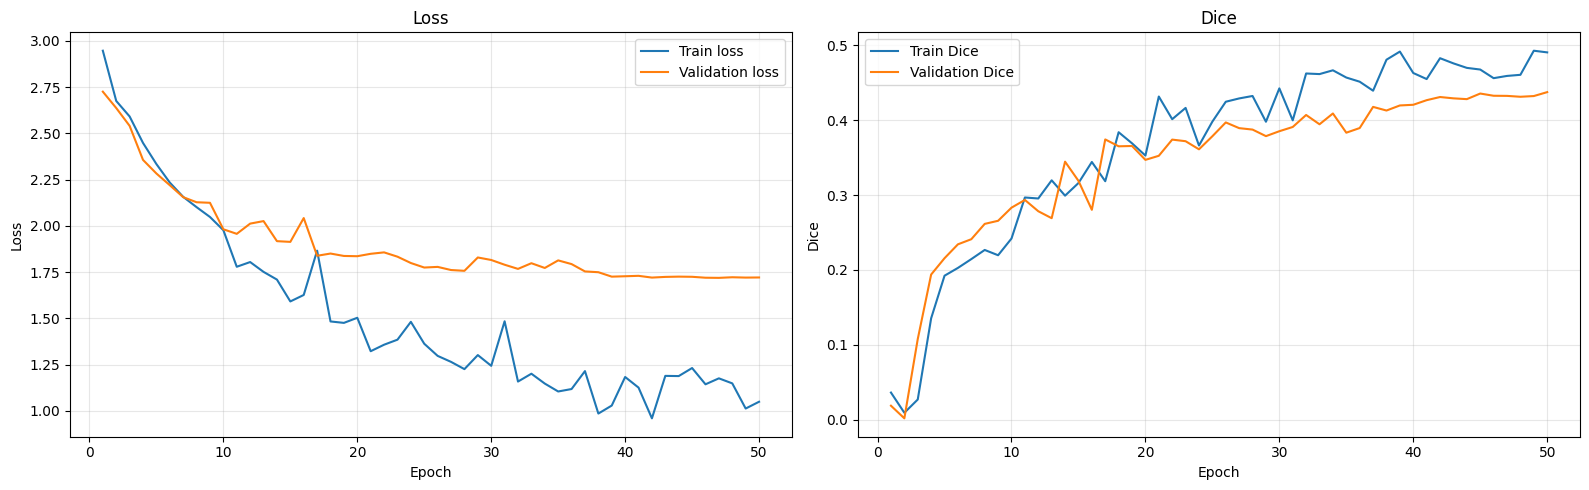

In [61]:
plot_history(history)

### Eval


In [62]:
evaluation_df = evaluate_model(
    model=model,
    loader=test_loader,
    device=device,
    num_classes=CONFIG["num_classes"],
    class_names=CLASS_NAMES,
)

evaluation_df.round(4)

,class_id,class_name,dice,iou,hd95,precision,recall
0,0,background,0.9855,0.9715,12.2023,0.9903,0.9808
1,1,non-neoplastic,0.3752,0.2309,28.9440,0.4211,0.3383
2,2,neoplastic,0.7612,0.6145,19.9923,0.6976,0.8376
3,macro_fg,macro_foreground_only,0.5682,0.4227,24.4682,0.5594,0.5880
4,macro_all,macro_all_classes,0.7073,0.6056,20.3795,0.7030,0.7189
